# فاز اول: فهم مسئله، ممیزی کیفیت داده و تحلیل اکتشافی (Track C: iNaturalist Fungi)
**پروژه درس تحلیل داده — پاییز ۱۴۰۵**  
**موضوع:** طبقه‌بندی چندوجهی گونه‌های قارچ و تمایز گونه‌های سمی از خوراکی با تصمیم‌گیری آگاه از ریسک

این نوت‌بوک، گزارش تعاملی و قابل بازتولید فاز اول پروژه است که خروجی‌های ممیزی ساختار، کیفیت داده، توزیع دنباله بلند (Long-Tail)، خطر نشت اطلاعات (Data Leakage) و خط مبنای اولیه را بارگذاری و نمایش می‌دهد.

In [1]:
import os
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

os.chdir('..') if os.path.basename(os.getcwd()) == 'notebooks' else None
print('Working Directory:', os.getcwd())

Working Directory: c:\Users\ASUS\Desktop\DataScience-Project


## ۱. بارگذاری خلاصه ممیزی ساختار و کیفیت داده (Data Quality Audit)

In [2]:
with open('reports/phase1/phase1_audit_summary.json', 'r', encoding='utf-8') as f:
    audit_summary = json.load(f)

print('=== خلاصه ممیزی کیفیت داده ===')
display(pd.Series(audit_summary['structure_and_quality']['quality_audit']).drop('missing_values_by_column'))

print('\n=== خلاصه ساختار سلسله‌مراتبی (Track C Hierarchy) ===')
display(pd.Series(audit_summary['structure_and_quality']['structure_audit']))

=== خلاصه ممیزی کیفیت داده ===


raw_observations_total                        9729
raw_photos_total                             17490
exact_duplicate_observations                    45
missing_or_impossible_gps_count                 56
extreme_positional_accuracy_gt_10km_count      116
captive_or_cultivated_count                     67
corrupt_photo_dimensions_count                  52
dtype: object


=== خلاصه ساختار سلسله‌مراتبی (Track C Hierarchy) ===


clean_observations_count                                                    9561
unique_taxa_count                                                             40
unique_families_count                                                         22
unique_observers_count                                                      1481
valid_photos_count                                                         17438
photos_per_observation         {'mean': 1.81, 'median': 1.0, 'max': 5, 'pct_m...
observations_per_observer      {'mean': 6.46, 'median': 3.0, 'max': 190, 'top...
regional_split                           {'north_america': 6884, 'europe': 2677}
toxicity_class_distribution    {'Edible': 5627, 'Deadly_Toxic': 2364, 'Inedib...
dtype: object

## ۲. بررسی جدول متادیتای سمیت ۴۰ گونه قارچ و داده‌های پاک‌سازی شده

In [3]:
df_species = pd.read_csv('data/species_toxicity_metadata.csv')
df_clean = pd.read_parquet('data/processed/phase1_audited_observations.parquet')
print(f'Clean Observations Shape: {df_clean.shape}')
df_species.head(10)

Clean Observations Shape: (9561, 28)


,species_idx,taxon_id,scientific_name,common_name,genus,family,toxicity_class,is_toxic_or_inedible,is_deadly,risk_level,lookalike_group,ecological_peak_month,ecological_month_std,ecological_lat_center,ecological_lat_std
0,1,50137,Amanita phalloides,Death Cap,Amanita,Amanitaceae,Deadly_Toxic,1,1,3,Gilled_White_Green_Cap,9.5,1.6,45.0,6.5
1,2,50274,Amanita muscaria,Fly Agaric,Amanita,Amanitaceae,Deadly_Toxic,1,1,3,Red_Orange_Amanita,9.5,1.6,45.0,6.5
2,3,50411,Amanita pantherina,Panther Cap,Amanita,Amanitaceae,Deadly_Toxic,1,1,3,Brown_Spotted_Amanita,9.5,1.6,45.0,6.5
3,4,50548,Amanita bisporigera,Eastern Destroying Angel,Amanita,Amanitaceae,Deadly_Toxic,1,1,3,Pure_White_Agaric,9.5,1.6,45.0,6.5
4,5,50685,Galerina marginata,Funeral Bell,Galerina,Hymenogastraceae,Deadly_Toxic,1,1,3,Wood_Dwelling_Brown,9.2,1.8,45.0,6.5
5,6,50822,Omphalotus illudens,Eastern Jack-o'-lantern,Omphalotus,Omphalotaceae,Deadly_Toxic,1,1,3,Orange_Chanterelle_Like,9.8,1.4,40.5,5.5
6,7,50959,Omphalotus olearius,Western/European Jack-o'-lantern,Omphalotus,Omphalotaceae,Deadly_Toxic,1,1,3,Orange_Chanterelle_Like,9.8,1.4,40.5,5.5
7,8,51096,Chlorophyllum molybdites,False Parasol (The Vomiter),Chlorophyllum,Agaricaceae,Deadly_Toxic,1,1,3,Large_Scaly_Parasol,9.0,2.0,43.0,7.0
8,9,51233,Gyromitra esculenta,False Morel,Gyromitra,Discinaceae,Deadly_Toxic,1,1,3,Brain_Honeycomb_Cap,4.8,1.0,48.0,6.0
9,10,51370,Hypholoma fasciculare,Sulfur Tuft,Hypholoma,Strophariaceae,Deadly_Toxic,1,1,3,Wood_Dwelling_Brown,10.0,1.9,46.5,6.5


## ۳. نمایش نمودارهای تحلیل اکتشافی (EDA) و ممیزی نشت اطلاعات


--- fig1_long_tail_distribution.png ---


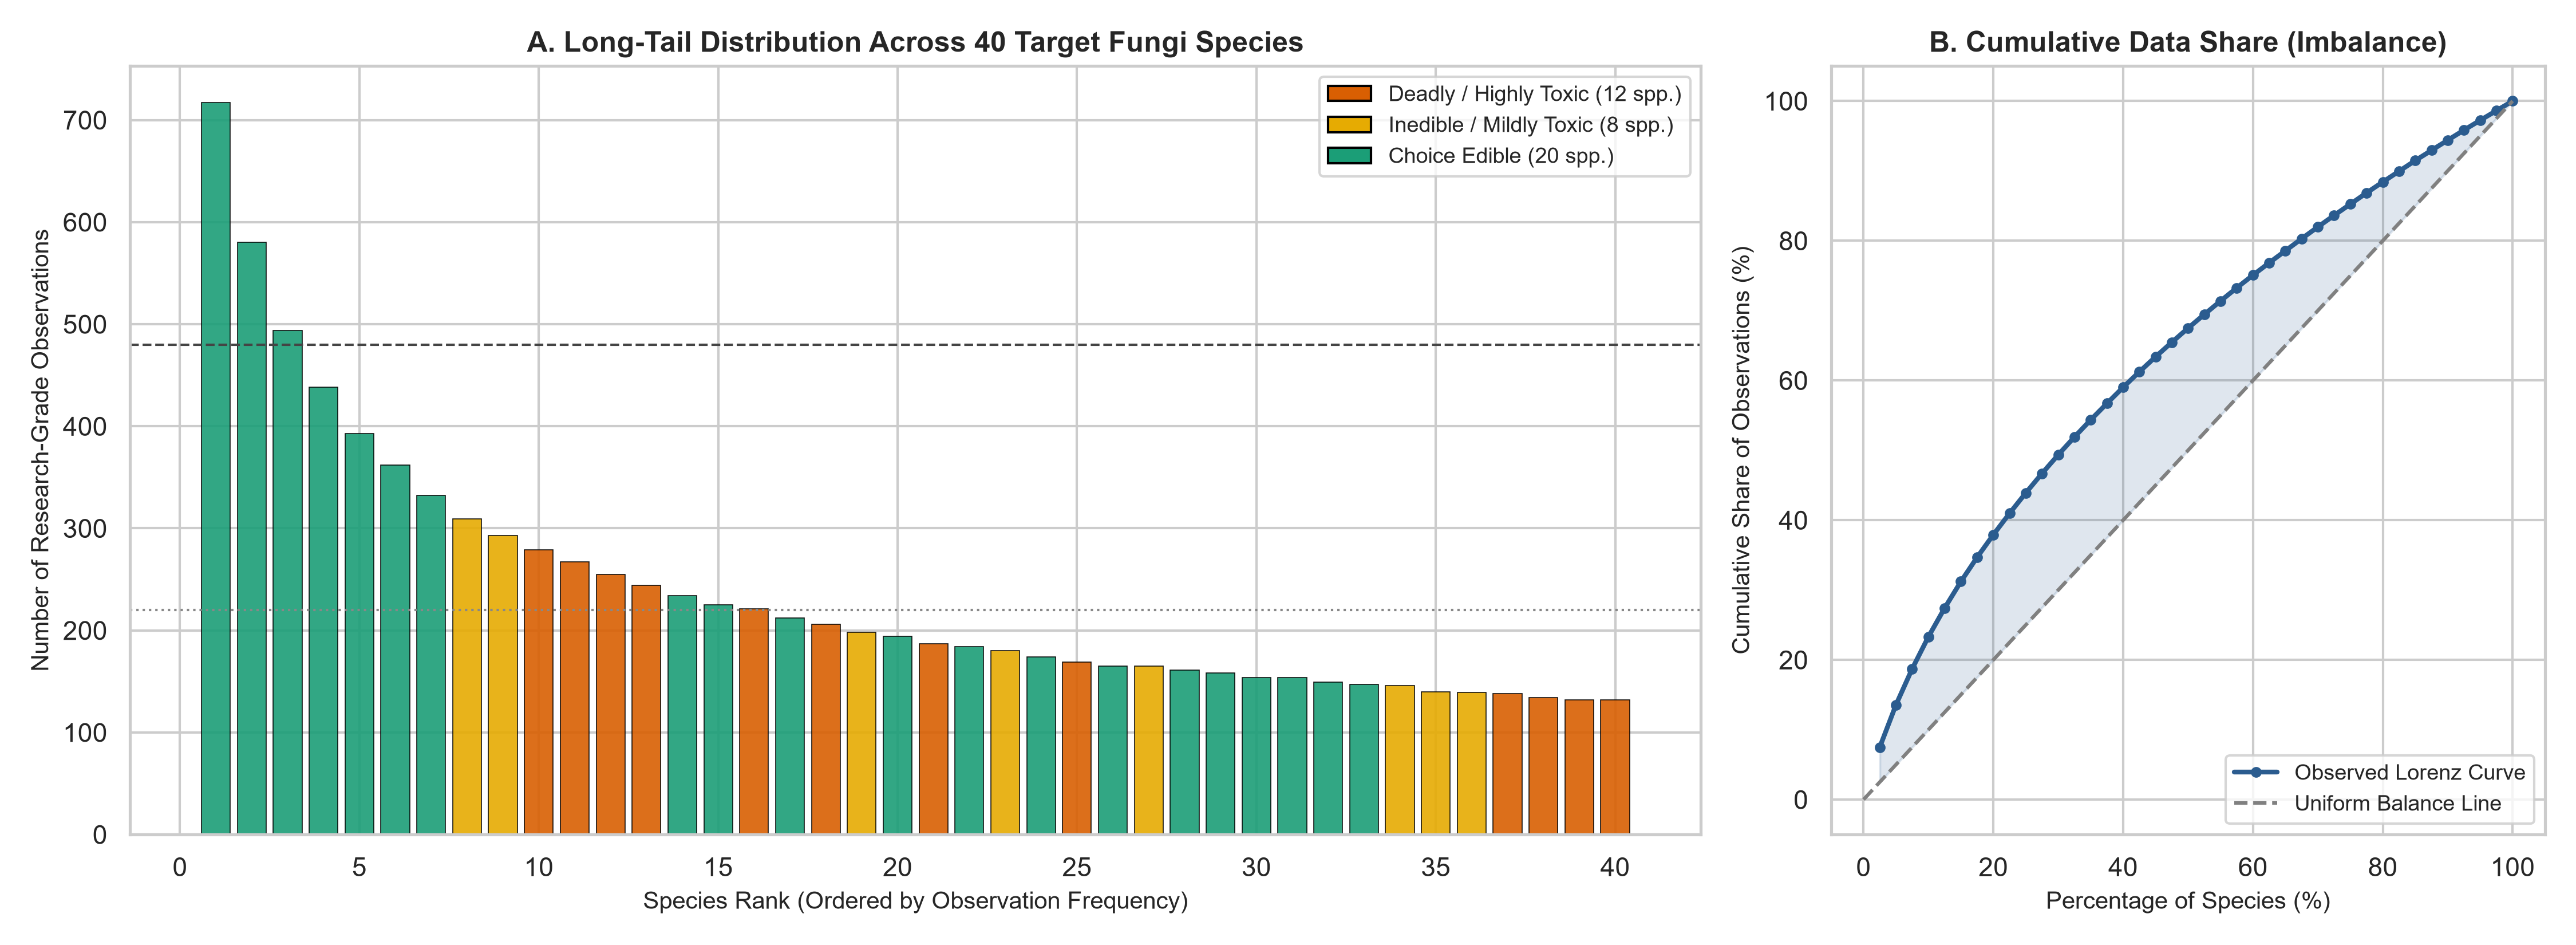


--- fig2_hierarchy_and_univariate_audit.png ---


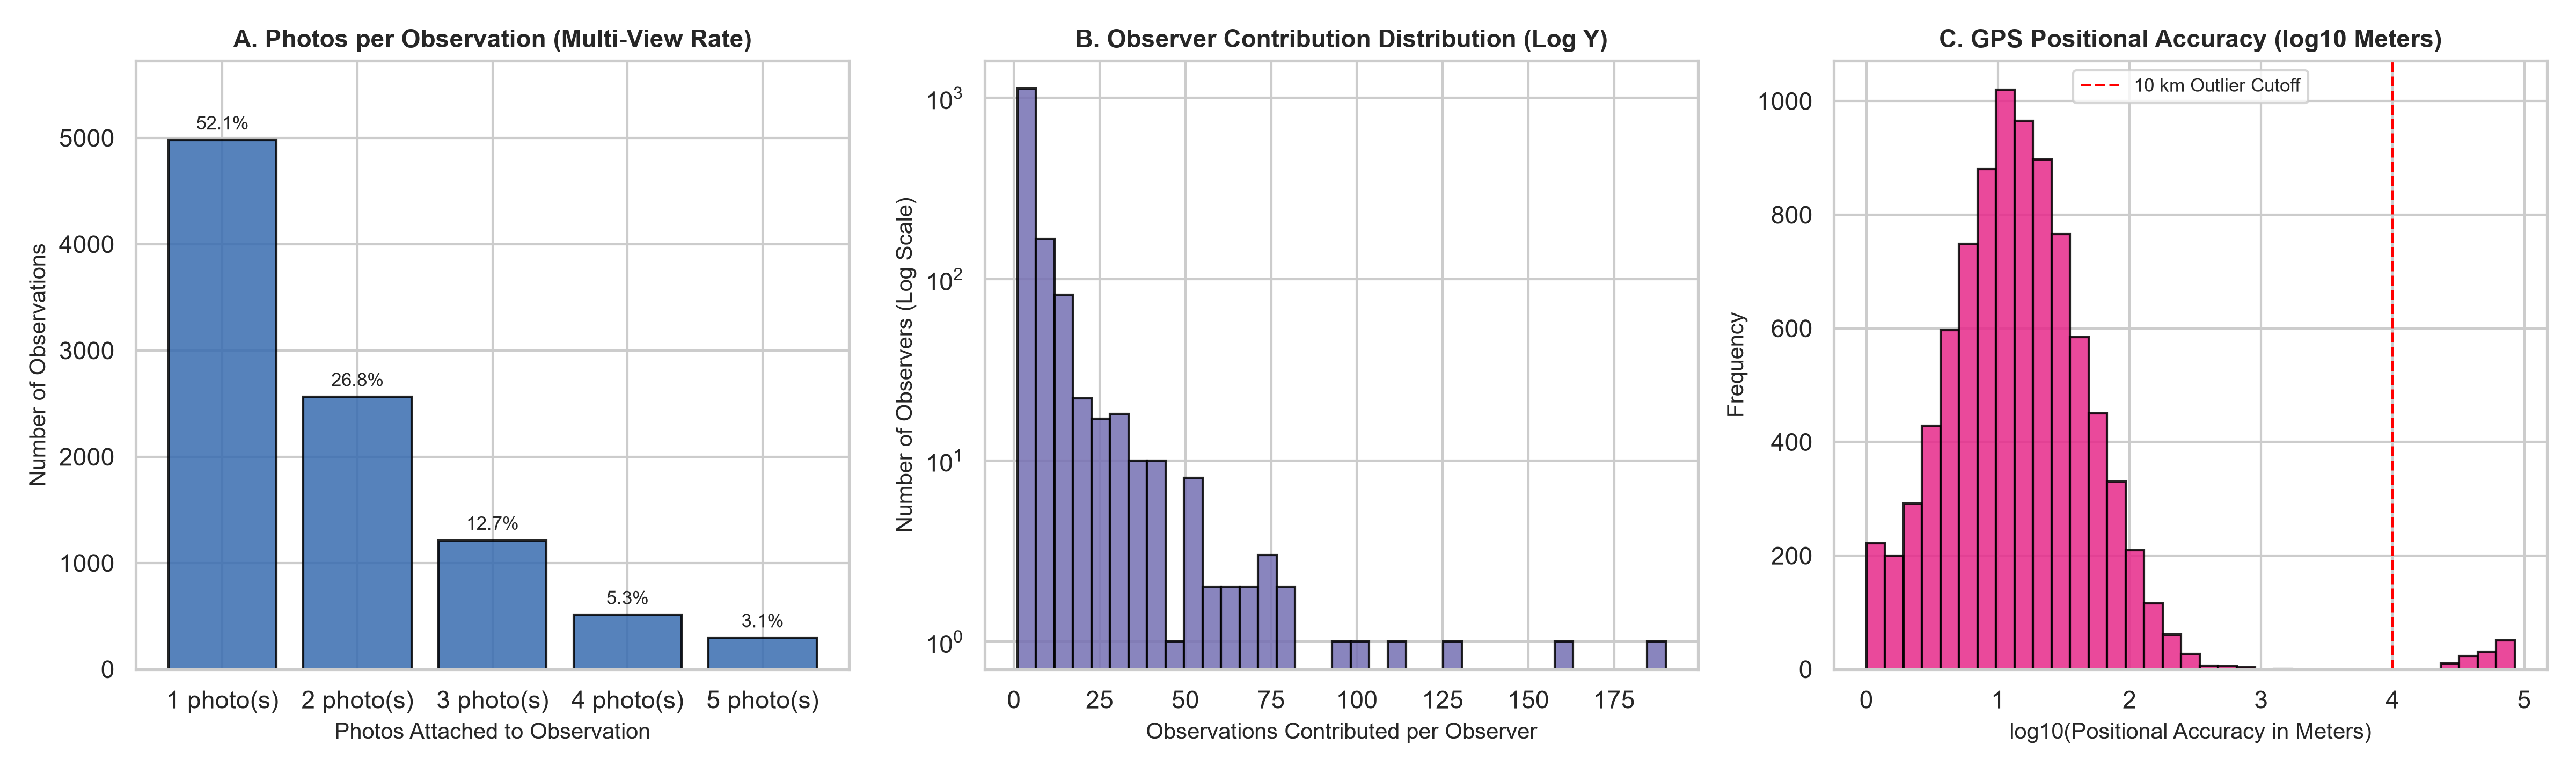


--- fig3_spatiotemporal_multivariate_patterns.png ---


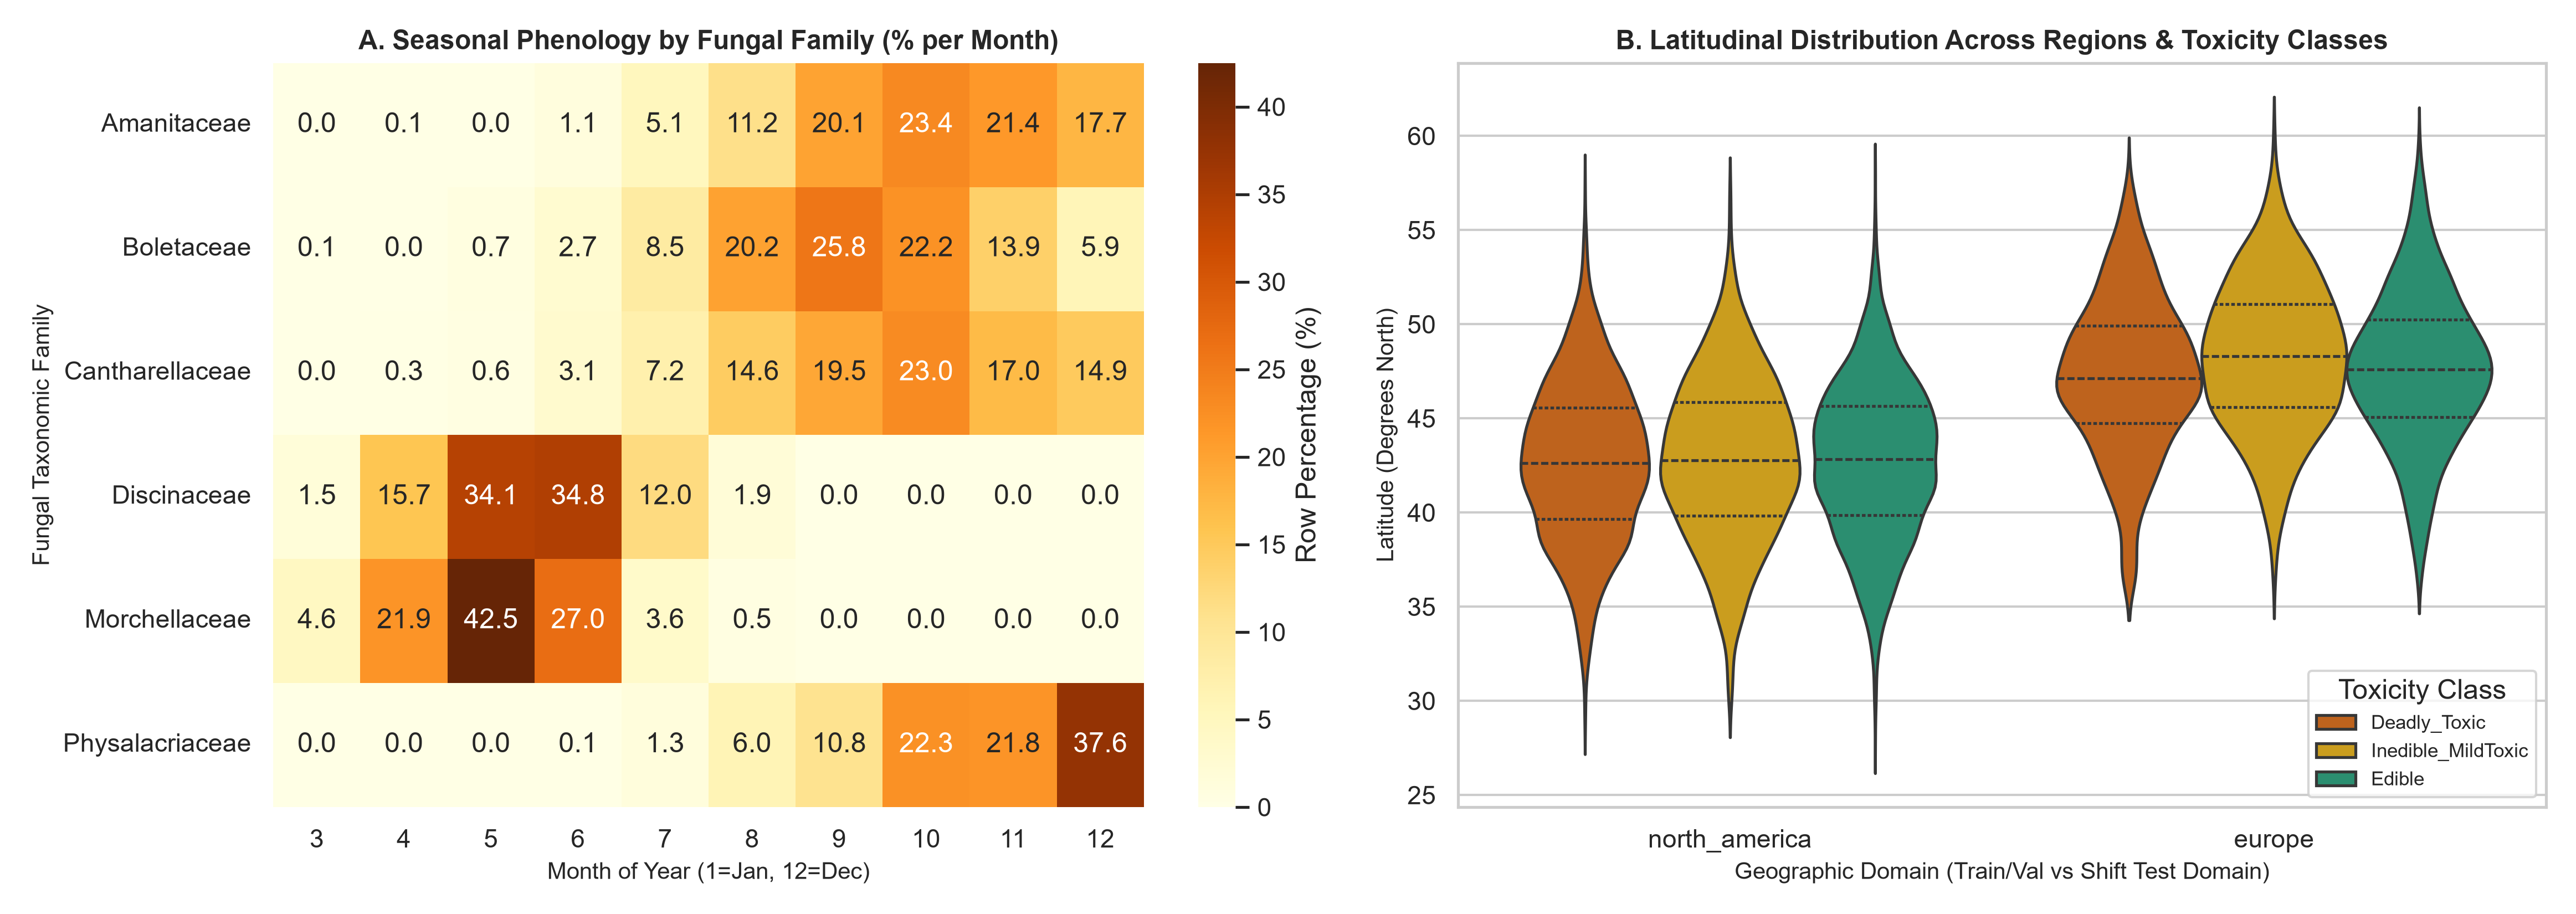


--- fig4_lookalike_risk_guilds.png ---


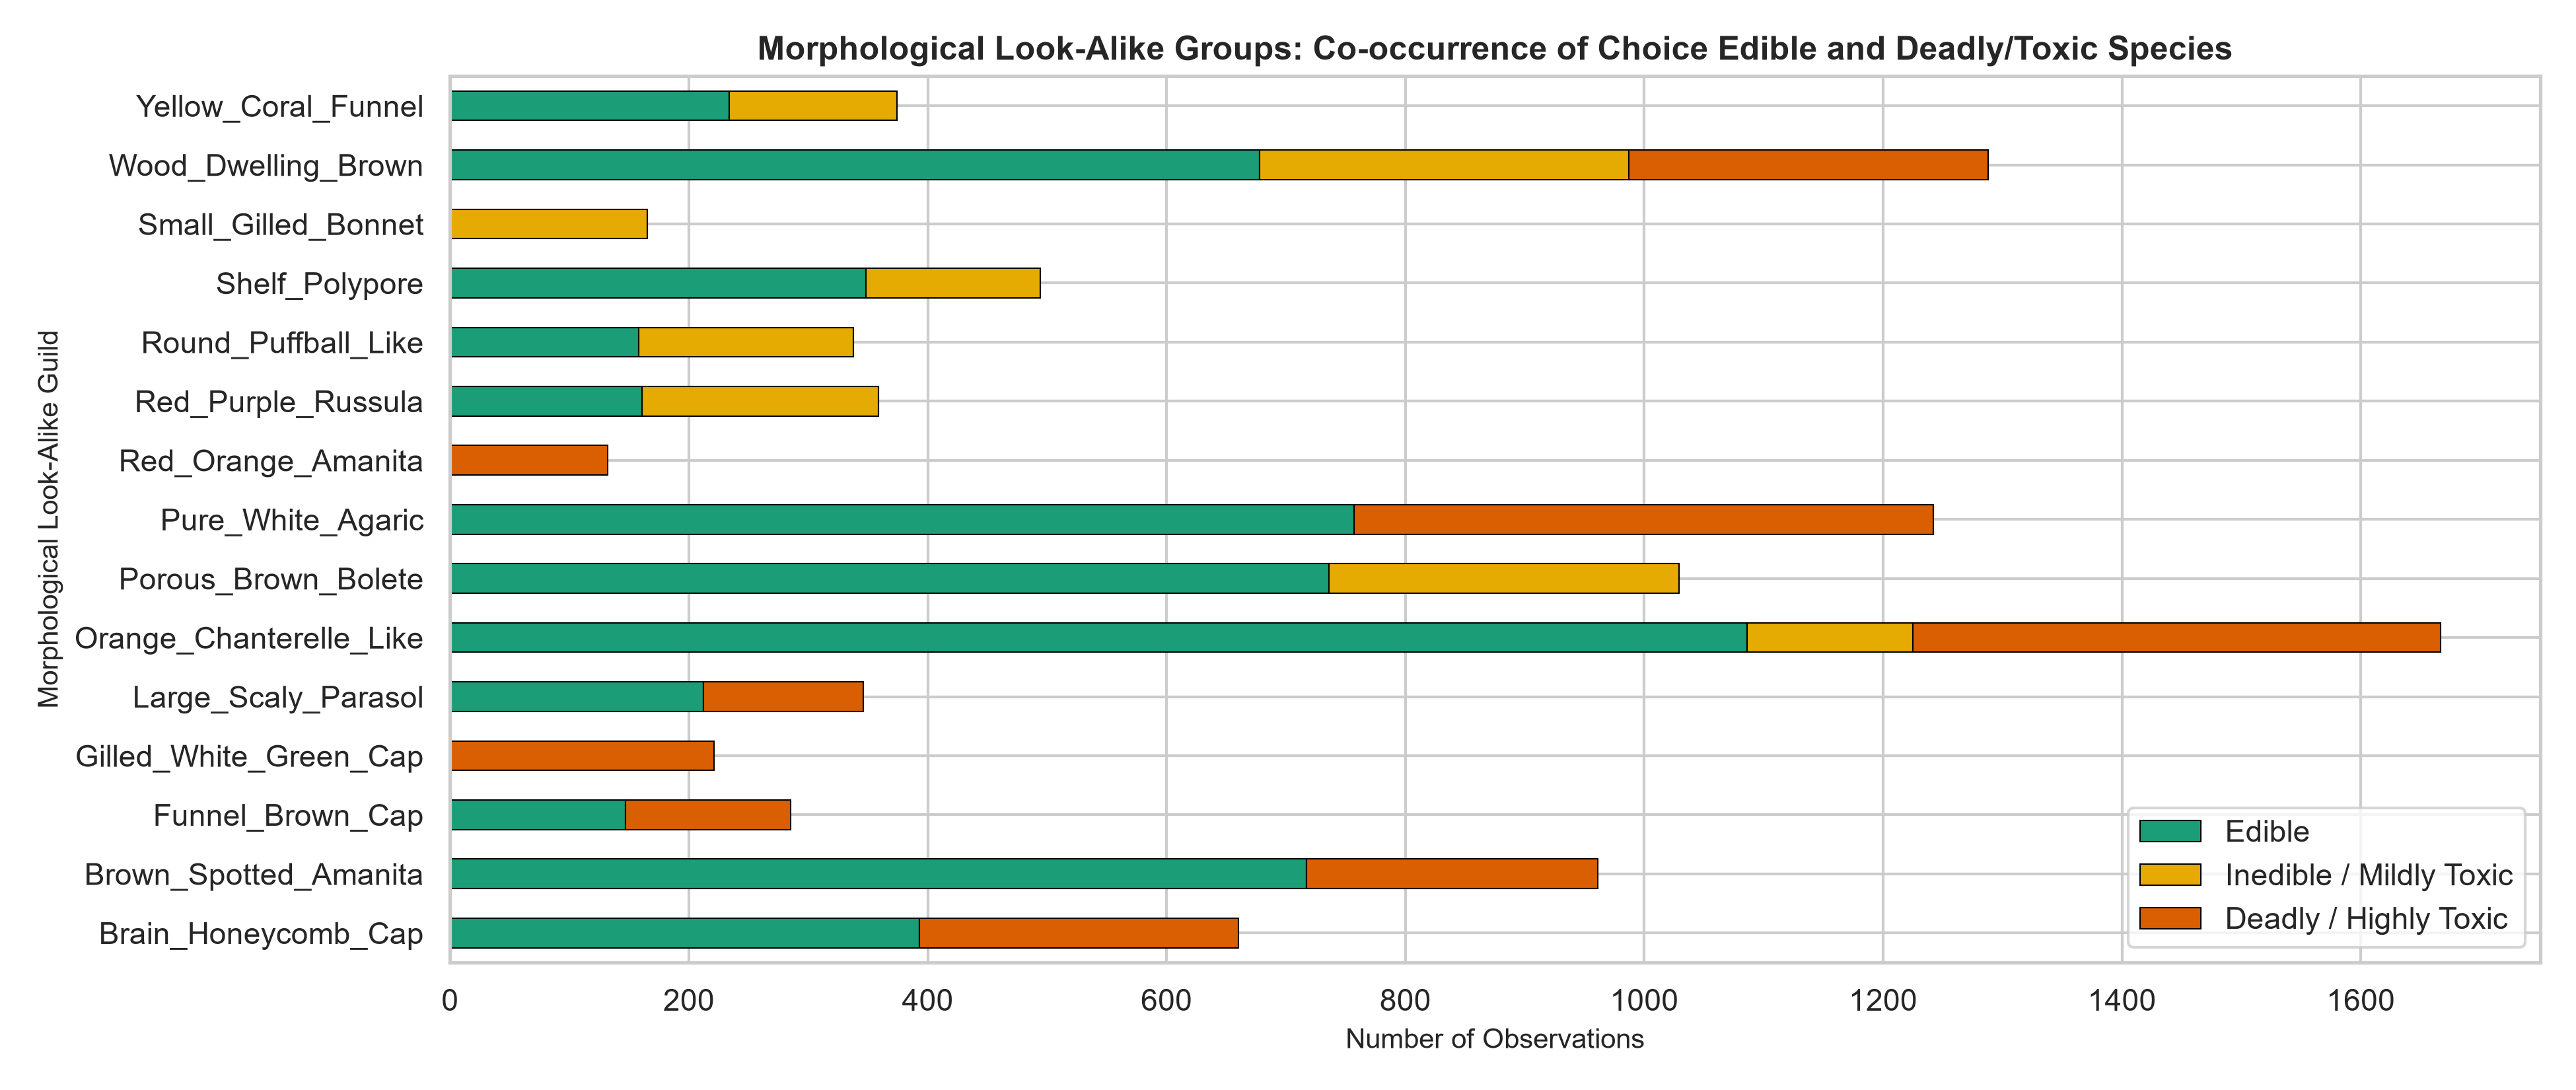


--- fig5_leakage_and_shortcut_baselines.png ---


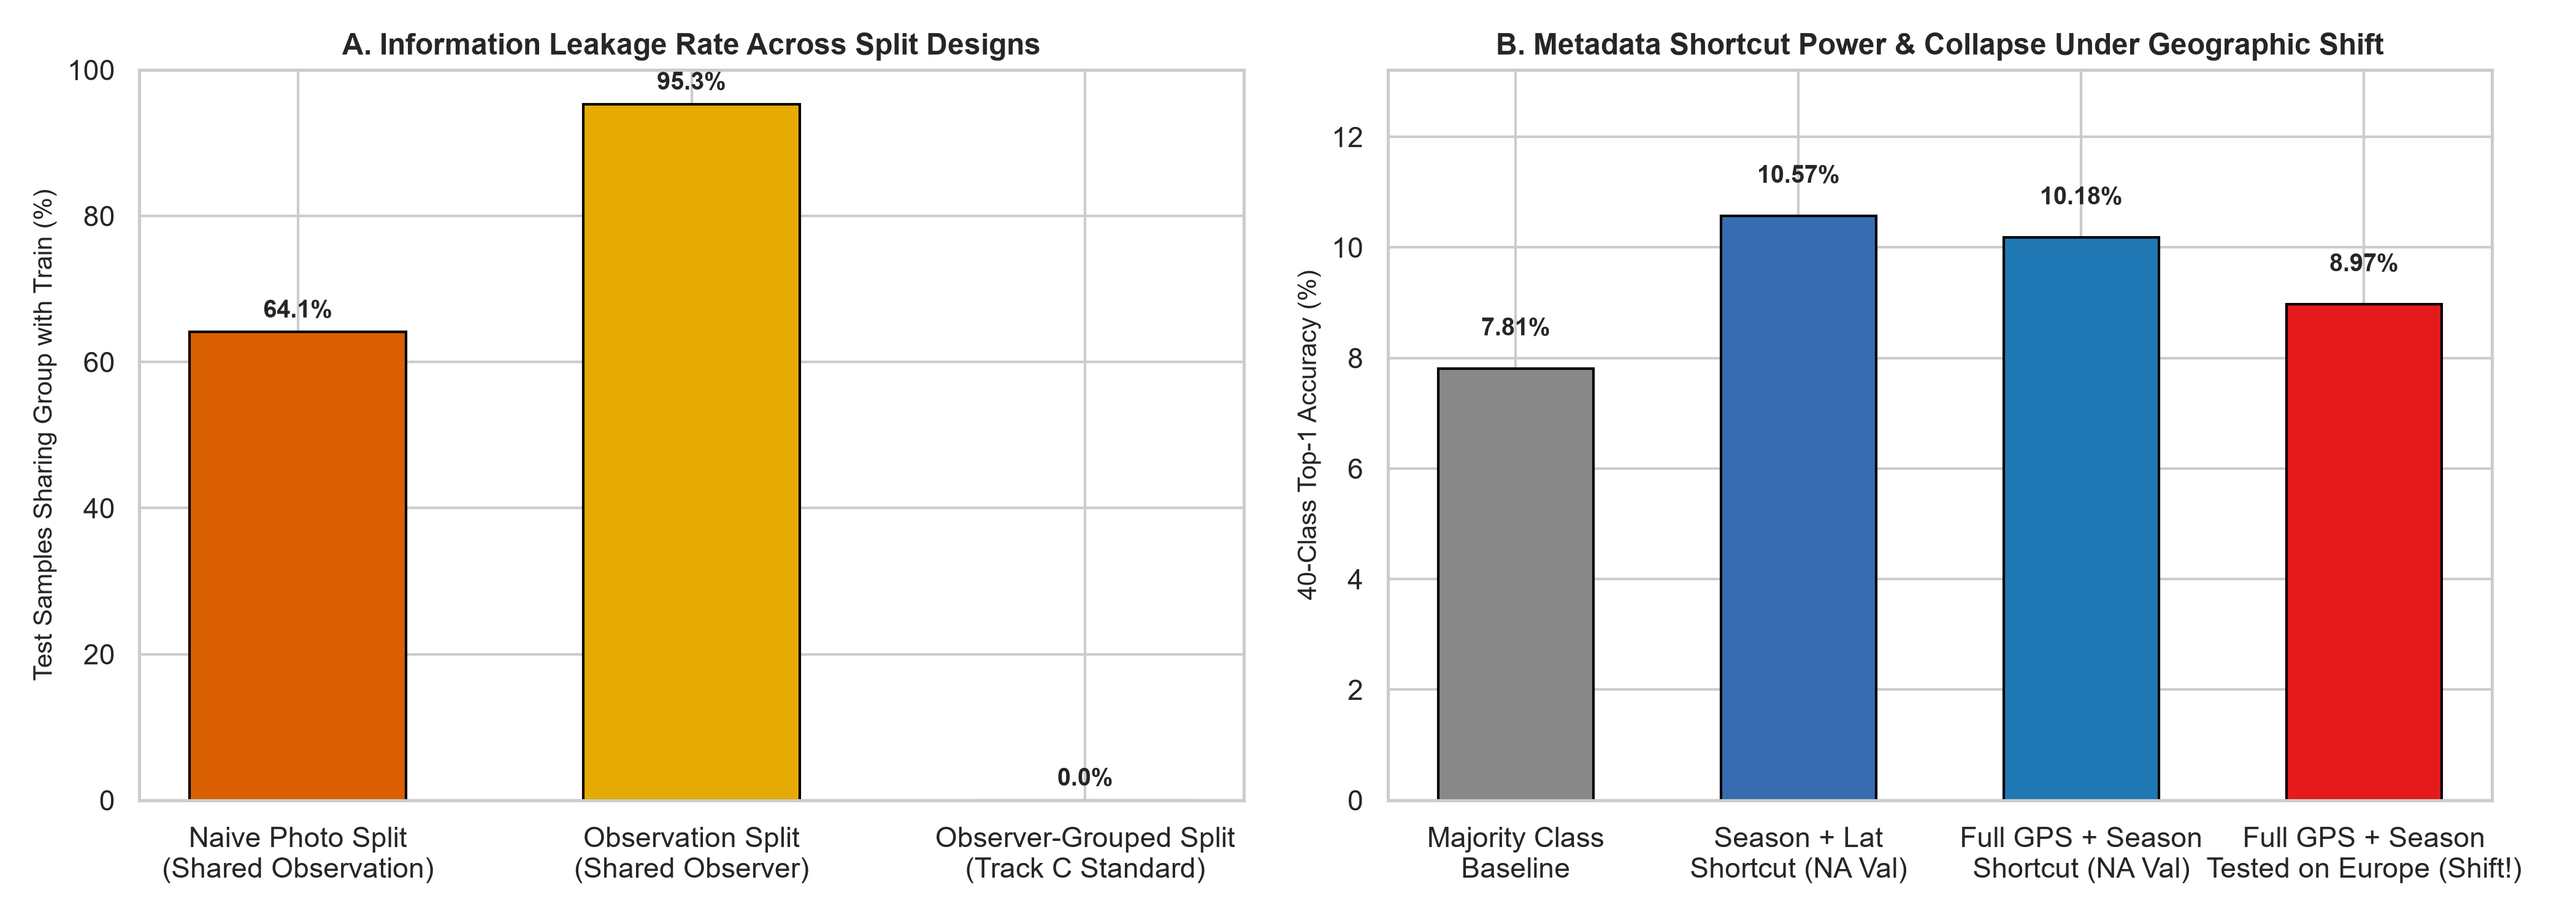

In [4]:
figure_files = [
    'figures/phase1/fig1_long_tail_distribution.png',
    'figures/phase1/fig2_hierarchy_and_univariate_audit.png',
    'figures/phase1/fig3_spatiotemporal_multivariate_patterns.png',
    'figures/phase1/fig4_lookalike_risk_guilds.png',
    'figures/phase1/fig5_leakage_and_shortcut_baselines.png',
]
for fig_path in figure_files:
    if os.path.exists(fig_path):
        print(f'\n--- {os.path.basename(fig_path)} ---')
        display(Image(filename=fig_path))

## ۴. نتایج کمی نشت اطلاعات (Data Leakage) و خط مبنای اولیه (Phase 1 Baselines)

In [5]:
print('=== Data Leakage Audit ===')
display(pd.Series(audit_summary['leakage_and_baselines']['leakage_audit']))

print('\n=== Phase 1 Baselines (40-Class Classification) ===')
display(pd.DataFrame(audit_summary['leakage_and_baselines']['phase1_baselines_40_classes']))

=== Data Leakage Audit ===


naive_photo_split_test_leakage_pct                64.09
naive_observation_split_observer_overlap_pct      95.30
observer_grouped_split_observation_overlap_pct     0.00
observer_grouped_split_observer_overlap_pct        0.00
dtype: float64


=== Phase 1 Baselines (40-Class Classification) ===


,random_guess_theoretical_accuracy_pct,majority_class_baseline,season_plus_latitude_baseline,full_lat_lon_season_shortcut_model
val_accuracy_pct,2.5,7.81,10.57,NaN
val_macro_f1_pct,2.5,0.36,3.22,NaN
val_balanced_acc_pct,2.5,NaN,5.38,NaN
in_domain_na_val_accuracy_pct,2.5,NaN,NaN,10.18
in_domain_na_val_macro_f1_pct,2.5,NaN,NaN,3.20
geographic_shift_eu_accuracy_pct,2.5,NaN,NaN,8.97
geographic_shift_eu_macro_f1_pct,2.5,NaN,NaN,3.01
